<a href="https://colab.research.google.com/github/jacline2003/card-fraud-analysis/blob/main/card_fraud_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#데이터 불러오기
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/fraudTest.csv')
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,SC,29209,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,UT,84002,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,NY,11710,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,FL,32780,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,MI,49632,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


In [ ]:
#표 크기 확인하기
df.shape

(555719, 23)

In [ ]:
#필요없는 열 지우고 모든 열 보이게
pd.set_option('display.max_columns', None)
df = df.drop(columns=['Unnamed: 0'])
df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,SC,29209,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,UT,84002,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,NY,11710,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,FL,32780,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,MI,49632,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


In [ ]:
#각 열에 어떤 종류 값이 들어있는지
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555719 entries, 0 to 555718
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   trans_date_trans_time  555719 non-null  object 
 1   cc_num                 555719 non-null  int64  
 2   merchant               555719 non-null  object 
 3   category               555719 non-null  object 
 4   amt                    555719 non-null  float64
 5   first                  555719 non-null  object 
 6   last                   555719 non-null  object 
 7   gender                 555719 non-null  object 
 8   street                 555719 non-null  object 
 9   city                   555719 non-null  object 
 10  state                  555719 non-null  object 
 11  zip                    555719 non-null  int64  
 12  lat                    555719 non-null  float64
 13  long                   555719 non-null  float64
 14  city_pop               555719 non-nu

In [ ]:
#빈칸&중복확인
print(df.isna().sum().sum())
print(df.duplicated(subset='trans_num').sum())

0
0


In [ ]:
#사기거래 몇건인지
print(df['is_fraud'].value_counts())
print(df['is_fraud'].value_counts(normalize=True))

is_fraud
0    553574
1      2145
Name: count, dtype: int64
is_fraud
0    0.99614
1    0.00386
Name: proportion, dtype: float64


In [ ]:
#글자로 된 날짜->진짜 날짜
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555719 entries, 0 to 555718
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   trans_date_trans_time  555719 non-null  datetime64[ns]
 1   cc_num                 555719 non-null  int64         
 2   merchant               555719 non-null  object        
 3   category               555719 non-null  object        
 4   amt                    555719 non-null  float64       
 5   first                  555719 non-null  object        
 6   last                   555719 non-null  object        
 7   gender                 555719 non-null  object        
 8   street                 555719 non-null  object        
 9   city                   555719 non-null  object        
 10  state                  555719 non-null  object        
 11  zip                    555719 non-null  int64         
 12  lat                    555719 non-null  floa

In [ ]:
#날짜에서 월 , 시간 뽑아 새 열 만들기
df['month'] = df['trans_date_trans_time'].dt.month
df['hour'] = df['trans_date_trans_time'].dt.hour
df[['trans_date_trans_time', 'month', 'hour']].head()

,trans_date_trans_time,month,hour
0,2020-06-21 12:14:25,6,12
1,2020-06-21 12:14:33,6,12
2,2020-06-21 12:14:53,6,12
3,2020-06-21 12:15:15,6,12
4,2020-06-21 12:15:17,6,12


In [ ]:
#월별 총 지출 계산
monthly = df.groupby('month')['amt'].sum().round(0)
monthly

,amt
month,
6,2079538.0
7,5938213.0
8,6133478.0
9,4911000.0
10,4868953.0
11,5028588.0
12,9603133.0


In [ ]:
# 6월이 유독 적은 이유: 데이터가 6월 21일부터 시작해서 열흘치만 들어 있음. - 소비가 줄어든 게 아님. 이렇게 숫자가 이상해 보이면 먼저 데이터 범위를 의심하는 습관이 중요
# 12월에 거의 2배로 늘어남: 11월 약 503만 달러에서 12월 약 960만 달러로 뛰었고, 연말 쇼핑 시즌 영향

In [ ]:
#카테고리별 총 지출(큰순서로정렬)
cat = df.groupby('category')['amt'].sum().round(0)
cat.sort_values(ascending=False)

,amt
category,
grocery_pos,6090122.0
shopping_pos,3827059.0
gas_transport,3583836.0
shopping_net,3487780.0
home,3035770.0
kids_pets,2800127.0
entertainment,2566048.0
misc_net,2151053.0
misc_pos,2149889.0


In [ ]:
#건수,합계,평균 한 번에 보기
cat_summary = df.groupby('category')['amt'].agg(['count', 'sum', 'mean']).round(1)
cat_summary.sort_values('sum', ascending=False)

,count,sum,mean
category,,,
grocery_pos,52553,6090121.6,115.9
shopping_pos,49791,3827058.6,76.9
gas_transport,56370,3583835.6,63.6
shopping_net,41779,3487780.0,83.5
home,52345,3035769.9,58.0
kids_pets,48692,2800126.6,57.5
entertainment,40104,2566048.0,64.0
misc_net,27367,2151052.7,78.6
misc_pos,34574,2149889.0,62.2


In [ ]:
#시간대별 사기 비율
fraud_by_hour = (df.groupby('hour')['is_fraud'].mean() * 100).round(2)
fraud_by_hour

,is_fraud
hour,
0,1.04
1,0.92
2,0.93
3,1.07
4,0.08
5,0.11
6,0.08
7,0.09
8,0.06


In [ ]:
#사기 거래 평균 금액
df.groupby('is_fraud')['amt'].mean().round(2)

,amt
is_fraud,
0,67.61
1,528.36


In [ ]:
df.groupby('month')['amt'].sum

<bound method GroupBy.sum of <pandas.core.groupby.generic.SeriesGroupBy object at 0x7a6e02cb6b10>>

In [ ]:
import matplotlib.pyplot as plt

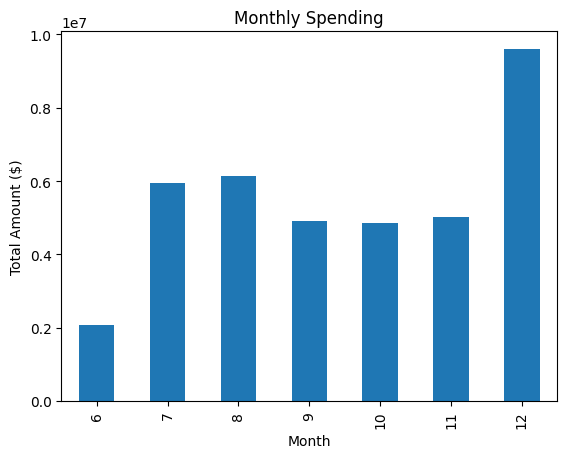

In [ ]:
#월별 지출 막대 차트
monthly.plot(kind='bar')
plt.title('Monthly Spending')
plt.xlabel('Month')
plt.ylabel('Total Amount ($)')
plt.show() #le7은 x천만 ex)0.8=800만달러

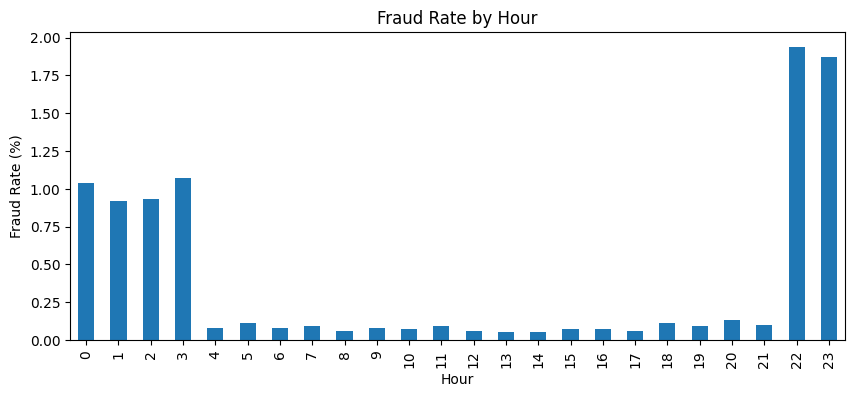

In [ ]:
#시간대별 사기 비율 막대 차트
fraud_by_hour.plot(kind='bar', figsize=(10, 4))
plt.title('Fraud Rate by Hour')
plt.xlabel('Hour')
plt.ylabel('Fraud Rate (%)')
plt.show()

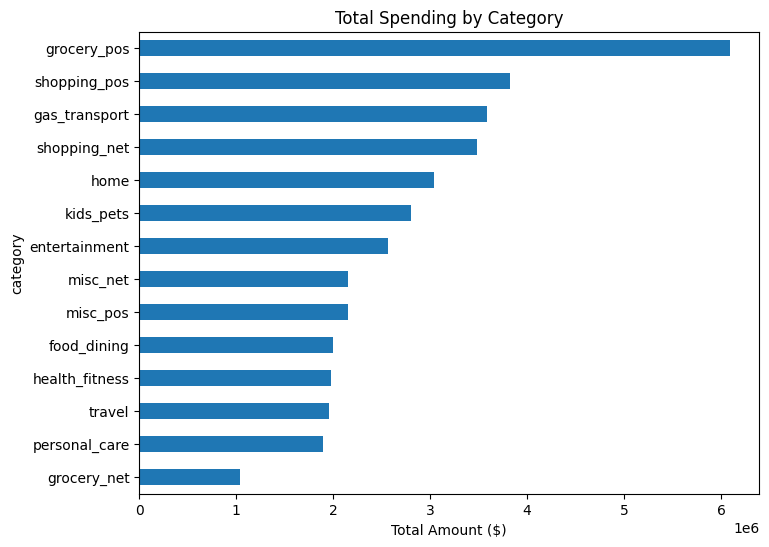

In [ ]:
#카테고리별 지출 가로 막대 차트
cat.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Total Spending by Category') #카테고리 이름은 길어서 세로막대로 그리면 글자가 비스듬히, 가로막대가 굿
plt.xlabel('Total Amount ($)')
plt.show()#le6=600만달러

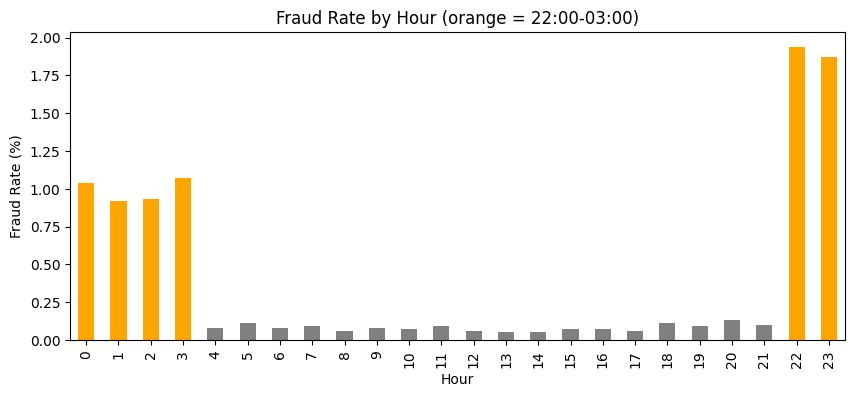

In [ ]:
colors = [] #밤시간대만 색깔로 강조하기
for h in fraud_by_hour.index:
    if h >= 22 or h <= 3:
        colors.append('orange')
    else:
        colors.append('gray')

fraud_by_hour.plot(kind='bar', figsize=(10, 4), color=colors)
plt.title('Fraud Rate by Hour (orange = 22:00-03:00)')
plt.xlabel('Hour')
plt.ylabel('Fraud Rate (%)')
plt.show()

In [ ]:
## SQL

import sqlite3#python에 있는 작은db

con = sqlite3.connect('card.db')
df.to_sql('transactions', con, index=False, if_exists='replace')
print('완료')

완료


In [ ]:
query = """
SELECT * --모든 열을 골라라. *는 "전부"
FROM transactions --transactions 테이블에서
LIMIT 5 -- 5줄만
"""
pd.read_sql_query(query, con) #pandas 의 df.head()같은 결과

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,month,hour
0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,SC,29209,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0,6,12
1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,UT,84002,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0,6,12
2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,NY,11710,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0,6,12
3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,FL,32780,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0,6,12
4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,MI,49632,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0,6,12


In [ ]:
#개수 세기,조건 걸기
query = """
SELECT COUNT(*) AS total_count, -- 행 개수 세기
       SUM(is_fraud) AS fraud_count -- is_fraud를 다 더함, 사기 건수
FROM transactions
"""
pd.read_sql_query(query, con)

,total_count,fraud_count
0,555719,2145


In [ ]:
#사기 거래만 남기는 필터
query = """
SELECT AVG(amt) AS avg_amt --남은 금액(사기거래금액) 평균
FROM transactions
WHERE is_fraud = 1 --사기거래만 남기기
"""
pd.read_sql_query(query, con)

,avg_amt
0,528.356494


In [ ]:
#월별지출(GROUP BY)
query = """
SELECT month,
       COUNT(*) AS tx_count,
       ROUND(SUM(amt), 0) AS total_amt
FROM transactions
GROUP BY month --월별로묶고 pandas의 groupby('month')역할
ORDER BY month --월 순서로 정렬 / 큰것부터 보려면 total_amt DESC
"""
pd.read_sql_query(query, con)

,month,tx_count,total_amt
0,6,30058,2079538.0
1,7,85848,5938213.0
2,8,88759,6133478.0
3,9,69533,4911000.0
4,10,69348,4868953.0
5,11,72635,5028588.0
6,12,139538,9603133.0


In [ ]:
# 카테고리별 집게
query = """
SELECT category,
       COUNT(*)           AS tx_count,    -- 건수
       ROUND(SUM(amt), 0) AS total_amt,   -- 합계
       ROUND(AVG(amt), 1) AS avg_amt      -- 평균
FROM transactions
GROUP BY category
ORDER BY total_amt DESC                   -- 합계 큰 순
"""
pd.read_sql_query(query, con)

,category,tx_count,total_amt,avg_amt
0,grocery_pos,52553,6090122.0,115.9
1,shopping_pos,49791,3827059.0,76.9
2,gas_transport,56370,3583836.0,63.6
3,shopping_net,41779,3487780.0,83.5
4,home,52345,3035770.0,58.0
5,kids_pets,48692,2800127.0,57.5
6,entertainment,40104,2566048.0,64.0
7,misc_net,27367,2151053.0,78.6
8,misc_pos,34574,2149889.0,62.2
9,food_dining,39268,1993948.0,50.8


In [ ]:
#case when 으로 거르기
query = """
SELECT CASE --조건에 따라 값을 정하겠다 =거르겠다
           WHEN hour >= 22 OR hour <= 3 THEN '심야' -- 시간이 22이상 3이하 - '심야'
           ELSE '주간' -- 그외에는 전부 '주간'
       END AS time_slot, -- 조건끝, 결과 열이름 : time_slot
       COUNT(*)                        AS tx_count,
       SUM(is_fraud)                   AS fraud_count,
       ROUND(AVG(is_fraud) * 100, 2)   AS fraud_rate_pct
FROM transactions
GROUP BY time_slot
"""
pd.read_sql_query(query, con)

,time_slot,tx_count,fraud_count,fraud_rate_pct
0,심야,130139,1807,1.39
1,주간,425580,338,0.08


In [ ]:
#금액대별 사기 비율
query = """
SELECT CASE --조건에 따라 거르겠다/1_,2_,3_ 붙인 이유: 정렬시 소액->중간->고액 순서로 나오게
           WHEN amt < 20  THEN '1_소액 (20달러 미만)'
           WHEN amt < 300 THEN '2_중간 (20~300달러)'
           ELSE                '3_고액 (300달러 이상)'
       END AS amt_group,
       COUNT(*)                        AS tx_count,
       SUM(is_fraud)                   AS fraud_count,
       ROUND(AVG(is_fraud) * 100, 2)   AS fraud_rate_pct
FROM transactions
GROUP BY amt_group
ORDER BY amt_group
"""
pd.read_sql_query(query, con)

,amt_group,tx_count,fraud_count,fraud_rate_pct
0,1_소액 (20달러 미만),182183,339,0.19
1,2_중간 (20~300달러),361388,407,0.11
2,3_고액 (300달러 이상),12148,1399,11.52


In [ ]:
#having으로 거르기
query = """
SELECT category,
       COUNT(*)                        AS tx_count,
       SUM(is_fraud)                   AS fraud_count,
       ROUND(AVG(is_fraud) * 100, 2)   AS fraud_rate_pct
FROM transactions
GROUP BY category
HAVING AVG(is_fraud) * 100 > 0.5
ORDER BY fraud_rate_pct DESC
"""
pd.read_sql_query(query, con)

,category,tx_count,fraud_count,fraud_rate_pct
0,shopping_net,41779,506,1.21
1,misc_net,27367,267,0.98
2,grocery_pos,52553,485,0.92


In [ ]:
#주의: 정수끼리 나누면 0나옴 -SQLite는 정수 ÷ 정수의 결과를 정수로 잘라버려요. 2145 ÷ 555719 = 0.0038...인데 소수점 아래를 버려서 0이됨.
query = """
SELECT SUM(is_fraud) / COUNT(*)          AS wrong,
       SUM(is_fraud) * 100.0 / COUNT(*)  AS right
FROM transactions
"""
pd.read_sql_query(query, con)

,wrong,right
0,0,0.385986


In [ ]:
#GROUP BY 와 윈도우 함수 차이
#GROUP BY
query = """
SELECT cc_num,--cc_num : 카드번호
       COUNT(*)           AS tx_count,
       ROUND(AVG(amt), 2) AS avg_amt
FROM transactions
GROUP BY cc_num
LIMIT 3
"""
pd.read_sql_query(query, con)

,cc_num,tx_count,avg_amt
0,60416207185,678,66.50
1,60422928733,669,57.43
2,60423098130,228,54.61


In [ ]:
#윈도우 함수
query = """
SELECT cc_num,
       trans_date_trans_time,
       amt,--OVER이 붙으면 윈도우 함수 ,amt 평균을 내되,줄을 압축하지마라
       ROUND(AVG(amt) OVER (PARTITION BY cc_num), 2) AS cust_avg
FROM transactions
WHERE cc_num = 30270432095985
LIMIT 5
"""
pd.read_sql_query(query, con)
#27단계에는 큰 문제가 하나 있어요. 60.36달러는 이 고객의 6개월 전체 평균이라서, 6월 21일 거래 옆에 12월 거래까지 포함된 평균이 붙어 있어요. 6월 21일 시점에는 12월에 얼마를 쓸지 알 수 없잖아요.실제 카드사는 결제가 들어오는 그 순간 수상한지 판단해야 해요. 그러니 그 시점까지 알 수 있었던 정보만 써야 해요. 미래 정보를 섞어 쓰는 실수를 데이터 누수라고 하는데, 면접에서 자주 나오는 개념이에요.

,cc_num,trans_date_trans_time,amt,cust_avg
0,30270432095985,2020-06-21 12:29:30,3.94,60.36
1,30270432095985,2020-06-21 15:09:01,3.09,60.36
2,30270432095985,2020-06-21 19:08:21,73.18,60.36
3,30270432095985,2020-06-22 04:03:19,42.38,60.36
4,30270432095985,2020-06-22 05:39:02,43.36,60.36


In [ ]:
#문제해결
query = """
SELECT trans_date_trans_time,
       amt,
       ROUND(AVG(amt) OVER (
           PARTITION BY cc_num
           ORDER BY unix_time --시간순서대로, unix time --거래시각을 초 단위로
           ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING
       ), 2) AS past_avg --OVER 괄호안에 두줄 추가
FROM transactions
WHERE cc_num = 30270432095985
LIMIT 5
"""
pd.read_sql_query(query, con)

,trans_date_trans_time,amt,past_avg
0,2020-06-21 12:29:30,3.94,NaN
1,2020-06-21 15:09:01,3.09,3.94
2,2020-06-21 19:08:21,73.18,3.51
3,2020-06-22 04:03:19,42.38,26.74
4,2020-06-22 05:39:02,43.36,30.65


In [ ]:
#사기가 일어난 순간 들여다보기- 이 고객(30270432095985)은 9월 23일 새벽부터 카드가 도용됐어요. 그 전후를 보면서, 평소 대비 몇 배를 썼는지(ratio)도 계산해 볼게요.
query = """
SELECT *
FROM (
    SELECT trans_date_trans_time,
           category,
           amt,
           is_fraud,
           ROUND(AVG(amt) OVER w, 2)       AS past_avg,--over w로
           ROUND(amt / AVG(amt) OVER w, 1) AS ratio
    FROM transactions
    WHERE cc_num = 30270432095985
    WINDOW w AS (PARTITION BY cc_num ORDER BY unix_time
                 ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
)
WHERE trans_date_trans_time BETWEEN '2020-09-22 18:00:00' AND '2020-09-25 00:00:00'
"""
pd.read_sql_query(query, con)

,trans_date_trans_time,category,amt,is_fraud,past_avg,ratio
0,2020-09-22 18:05:33,health_fitness,8.17,0,57.55,0.1
1,2020-09-22 19:55:16,home,42.37,0,57.48,0.7
2,2020-09-22 21:54:39,health_fitness,59.65,0,57.45,1.0
3,2020-09-22 22:38:51,shopping_net,1.23,0,57.46,0.0
4,2020-09-23 02:20:52,grocery_pos,360.71,1,57.37,6.3
5,2020-09-23 11:00:46,gas_transport,12.54,1,57.84,0.2
6,2020-09-23 22:51:35,home,258.37,1,57.77,4.5
7,2020-09-23 22:54:15,kids_pets,19.81,1,58.09,0.3
8,2020-09-23 23:17:57,personal_care,18.68,1,58.03,0.3
9,2020-09-23 23:54:08,shopping_pos,1083.04,1,57.97,18.7


In [ ]:
##24시간동안 몇 번, 얼마나 썼나
query = """
SELECT *
FROM (
    SELECT trans_date_trans_time,
           amt,
           is_fraud,
           COUNT(*) OVER w24           AS cnt_24h,
           ROUND(SUM(amt) OVER w24, 0) AS amt_24h
    FROM transactions
    WHERE cc_num = 30270432095985
    WINDOW w24 AS (PARTITION BY cc_num ORDER BY unix_time
                   RANGE BETWEEN 86400 PRECEDING AND CURRENT ROW)
)
WHERE trans_date_trans_time BETWEEN '2020-09-22 18:00:00' AND '2020-09-25 00:00:00'
"""
pd.read_sql_query(query, con)

,trans_date_trans_time,amt,is_fraud,cnt_24h,amt_24h
0,2020-09-22 18:05:33,8.17,0,8,259.0
1,2020-09-22 19:55:16,42.37,0,9,302.0
2,2020-09-22 21:54:39,59.65,0,7,323.0
3,2020-09-22 22:38:51,1.23,0,7,199.0
4,2020-09-23 02:20:52,360.71,1,7,531.0
5,2020-09-23 11:00:46,12.54,1,8,544.0
6,2020-09-23 22:51:35,258.37,1,3,632.0
7,2020-09-23 22:54:15,19.81,1,4,651.0
8,2020-09-23 23:17:57,18.68,1,5,670.0
9,2020-09-23 23:54:08,1083.04,1,6,1753.0


In [ ]:
#계산함수() OVER (
#    PARTITION BY 누구별로
#   ORDER BY 어떤 순서로
#    ROWS 또는 RANGE BETWEEN 어디부터 AND 어디까지
#)

In [ ]:
#55만건 전체 평소 패턴 계산
query = """
WITH step1 AS (
    -- 1단계: 과거 이력과 최근 24시간 집계
    SELECT cc_num, trans_date_trans_time, unix_time, category, amt, hour, is_fraud,
           CASE WHEN hour >= 22 OR hour <= 3 THEN 1 ELSE 0 END AS is_night,
           COUNT(*)       OVER w_past AS past_cnt,     -- 이전 거래 수
           AVG(amt)       OVER w_past AS past_avg,     -- 이전 평균 금액
           SUM(amt)       OVER w_past AS past_total,   -- 이전 총 지출
           MIN(unix_time) OVER w_past AS first_time,   -- 첫 거래 시각
           SUM(amt)       OVER w_24h  AS amt_24h       -- 최근 24시간 지출
    FROM transactions
    WINDOW w_past AS (PARTITION BY cc_num ORDER BY unix_time
                      ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),
           w_24h  AS (PARTITION BY cc_num ORDER BY unix_time
                      RANGE BETWEEN 86400 PRECEDING AND CURRENT ROW)
),
step2 AS (
    -- 2단계: 1단계 결과로 하루 평균 지출과 '평소의 3배 이상' 여부 계산
    SELECT *,
           past_total / ((unix_time - first_time) / 86400.0) AS daily_avg,
           CASE WHEN past_cnt >= 10 AND amt >= 3 * past_avg THEN 1 ELSE 0 END AS is_big -- (평소의 3배인가) 1단계에서 past_avg구하고 2단계에서 is_big
    FROM step1 --step1을 재료로 step2를
)
-- 3단계: 최근 24시간 안의 심야 결제 수, 고액 결제 수
SELECT *,
       SUM(is_night) OVER w_24h AS night_cnt_24h,
       SUM(is_big)   OVER w_24h AS big_cnt_24h
FROM step2
WINDOW w_24h AS (PARTITION BY cc_num ORDER BY unix_time
                 RANGE BETWEEN 86400 PRECEDING AND CURRENT ROW)
"""
features = pd.read_sql_query(query, con)
features.shape

(555719, 17)

In [ ]:
#규칙 만들기 전, 사기와 정상 차이 확인
cols = ['amt', 'amt_24h', 'night_cnt_24h', 'big_cnt_24h']
features.groupby('is_fraud')[cols].median()

,amt,amt_24h,night_cnt_24h,big_cnt_24h
is_fraud,,,,
0,47.15,272.78,1.0,0.0
1,371.94,2338.50,4.0,3.0


In [ ]:
#규칙만들기, 걸리면1 아니면0
enough = features['past_cnt'] >= 10

features['r1_big_amount']   = (enough & (features['amt'] >= 3 * features['past_avg'])).astype(int)
features['r2_spend_surge']  = (enough & (features['amt_24h'] >= 4 * features['daily_avg'])).astype(int)
features['r3_night_repeat'] = (features['night_cnt_24h'] >= 3).astype(int)
features['r4_big_repeat']   = (features['big_cnt_24h'] >= 3).astype(int)

rules = ['r1_big_amount', 'r2_spend_surge', 'r3_night_repeat', 'r4_big_repeat']
features[rules].sum()

,0
r1_big_amount,22628
r2_spend_surge,25208
r3_night_repeat,85601
r4_big_repeat,2810


In [ ]:
#규칙을 합쳐서 점수 매기기
features['score'] = features[rules].sum(axis=1)

score_table = features.groupby('score')['is_fraud'].agg(['count', 'sum', 'mean'])
score_table['mean'] = (score_table['mean'] * 100).round(2)
score_table

,count,sum,mean
score,,,
0,438433,167,0.04
1,102126,358,0.35
2,12336,290,2.35
3,1847,473,25.61
4,977,857,87.72


In [ ]:
#규칙 혼동 행렬 계산
features['alert'] = (features['score'] >= 3).astype(int)

is_alert = features['alert'] == 1
is_fraud = features['is_fraud'] == 1

tp = (is_alert & is_fraud).sum()      # 경보 O, 실제 사기 O
fp = (is_alert & ~is_fraud).sum()     # 경보 O, 실제 정상
fn = (~is_alert & is_fraud).sum()     # 경보 X, 실제 사기
tn = (~is_alert & ~is_fraud).sum()    # 경보 X, 실제 정상

print('정탐 TP:', tp, '/ 오탐 FP:', fp, '/ 미탐 FN:', fn, '/ 정상 TN:', tn)
print('정밀도:', round(tp / (tp + fp) * 100, 1), '%')
print('재현율:', round(tp / (tp + fn) * 100, 1), '%')
print('정확도:', round((tp + tn) / len(features) * 100, 2), '%')

정탐 TP: 1330 / 오탐 FP: 1494 / 미탐 FN: 815 / 정상 TN: 552080
정밀도: 47.1 %
재현율: 62.0 %
정확도: 99.58 %


In [ ]:
#몇 점부터 경보를 울릴지
days = 194   # 데이터 기간: 2020-06-21 ~ 2020-12-31
total_fraud = features['is_fraud'].sum()

rows = []
for k in [1, 2, 3, 4]: #같은계산 반복
    alert = features['score'] >= k
    n_alert = alert.sum()
    tp = (alert & (features['is_fraud'] == 1)).sum()
    rows.append({
        '기준': f'{k}점 이상',
        '경보 수': n_alert,
        '하루 경보': round(n_alert / days, 1),
        '정밀도(%)': round(tp / n_alert * 100, 1),
        '재현율(%)': round(tp / total_fraud * 100, 1),
    })

pd.DataFrame(rows)

,기준,경보 수,하루 경보,정밀도(%),재현율(%)
0,1점 이상,117286,604.6,1.7,92.2
1,2점 이상,15160,78.1,10.7,75.5
2,3점 이상,2824,14.6,47.1,62.0
3,4점 이상,977,5.0,87.7,40.0


In [ ]:
#도용 카드를 몇 장 잡았고, 피해를 얼마나 막았는지
fraud = features[features['is_fraud'] == 1].sort_values(['cc_num', 'unix_time']).copy()

# 카드별로 첫 경보 이후는 계속 1 (카드 정지됨)
fraud['blocked'] = fraud.groupby('cc_num')['alert'].cummax()

total_cards  = fraud['cc_num'].nunique()
caught_cards = fraud.groupby('cc_num')['alert'].max().sum()
total_loss   = fraud['amt'].sum()
saved_loss   = fraud.loc[fraud['blocked'] == 1, 'amt'].sum()

print('도용 카드:', total_cards, '장 중', caught_cards, '장 탐지')
print('전체 사기 금액:', round(total_loss), '달러')
print('막을 수 있었던 금액:', round(saved_loss), '달러 (', round(saved_loss / total_loss * 100, 1), '%)')

도용 카드: 218 장 중 183 장 탐지
전체 사기 금액: 1133325 달러
막을 수 있었던 금액: 817685 달러 ( 72.1 %)


In [ ]:
#월별로 규칙이 잘 작동하는지 (성능일정한지)
features['month'] = features['trans_date_trans_time'].str[:7]

alerts = features[features['alert'] == 1]
monthly = alerts.groupby('month')['is_fraud'].agg(['count', 'sum', 'mean'])
monthly['mean'] = (monthly['mean'] * 100).round(1)
monthly

,count,sum,mean
month,,,
2020-06,99,56,56.6
2020-07,334,162,48.5
2020-08,448,297,66.3
2020-09,288,197,68.4
2020-10,333,246,73.9
2020-11,293,199,67.9
2020-12,1029,173,16.8
